Прогноз default по кредитным картам

Сравниваю последний месяц и полную историю платежей
Данные UCI, 30 000 клиентов из Тайваня, апрель-сентябрь 2005 года
Target оставляю исходным, default payment next month, выход модели от 0 до 1
Одна строка соответствует клиенту, целевой месяц у всех общий

Загрузка данных

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen
from hashlib import sha256
from importlib.metadata import version
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display, Markdown
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEED = 42
ROOT = Path.cwd()
DATA = ROOT / 'data'
ARTIFACTS = ROOT / 'artifacts'
DATA.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (9, 4.4), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .2, 'font.size': 10,
})
VERSIONS = {p: version(p) for p in [
    'numpy', 'pandas', 'scipy', 'scikit-learn', 'catboost', 'duckdb', 'matplotlib', 'xlrd',
]}

In [2]:
UCI_URL = ('https://archive.ics.uci.edu/static/public/350/'
           'default%2Bof%2Bcredit%2Bcard%2Bclients.zip')
EXPECTED_SHA256 = '56c885f84457f6680f8438f02bfcdac9579323d8a94465ee5f26e32baa727602'
archive = DATA / 'uci_350.zip'
if not archive.exists():
    
    with urlopen(UCI_URL, timeout=90) as response:
        payload = response.read()
    temporary = DATA / 'uci_350.zip.part'
    temporary.write_bytes(payload)
    temporary.replace(archive)
assert sha256(archive.read_bytes()).hexdigest() == EXPECTED_SHA256
with ZipFile(archive) as z:
    members = [name for name in z.namelist() if name.endswith('.xls')]
    df = pd.read_excel(BytesIO(z.read(members[0])), header=1, engine='xlrd')

df = df.rename(columns={'default payment next month': 'target'})
df.columns = df.columns.str.strip()
STATUS = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
BILLS = [f'BILL_AMT{i}' for i in range(1, 7)]
PAYMENTS = [f'PAY_AMT{i}' for i in range(1, 7)]
GENERAL = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
RAW_FEATURES = GENERAL + STATUS + BILLS + PAYMENTS
assert df.ID.is_unique and set(df.target.unique()) == {0, 1}
display(df.head(3))

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


Проверка данных

In [3]:
schema = pd.DataFrame({
    'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
    'unique': df.nunique(), 'min': df.min(), 'max': df.max(),
})
display(schema)
non_id = [c for c in df.columns if c != 'ID']
profile_sizes = df.groupby(RAW_FEATURES, dropna=False).size()
conflicting_profiles = (
    df.groupby(RAW_FEATURES, dropna=False).target.nunique().gt(1).sum()
)
audit = {
    'clients': len(df), 'features': len(RAW_FEATURES),
    'missing_cells': int(df.isna().sum().sum()),
    'full_row_duplicates': int(df.duplicated().sum()),
    'duplicates_without_ID': int(df.duplicated(non_id).sum()),
    'duplicate_predictors_excess_rows': int(df.duplicated(RAW_FEATURES).sum()),
    'clients_in_repeated_predictor_profiles': int(profile_sizes[profile_sizes > 1].sum()),
    'conflicting_predictor_profiles': int(conflicting_profiles),
    'positive_count': int(df.target.sum()), 'positive_rate': float(df.target.mean()),
    'nonpositive_limits': int(df.LIMIT_BAL.le(0).sum()),
    'negative_bill_cells': int(df[BILLS].lt(0).sum().sum()),
    'negative_payment_cells': int(df[PAYMENTS].lt(0).sum().sum()),
}
display(pd.Series(audit, name='audit'))
display(df[['LIMIT_BAL', *BILLS, *PAYMENTS]].describe(percentiles=[.01, .5, .95, .99]).T)

,dtype,missing,unique,min,max
ID,int64,0,30000,1,30000
LIMIT_BAL,int64,0,81,10000,1000000
SEX,int64,0,2,1,2
EDUCATION,int64,0,7,0,6
MARRIAGE,int64,0,4,0,3
AGE,int64,0,56,21,79
PAY_0,int64,0,11,-2,8
PAY_2,int64,0,11,-2,8
PAY_3,int64,0,11,-2,8
PAY_4,int64,0,11,-2,8


clients                                  30,000.0000
features                                     23.0000
missing_cells                                 0.0000
full_row_duplicates                           0.0000
duplicates_without_ID                        35.0000
duplicate_predictors_excess_rows             56.0000
clients_in_repeated_predictor_profiles      108.0000
conflicting_predictor_profiles               21.0000
positive_count                            6,636.0000
positive_rate                                 0.2212
nonpositive_limits                            0.0000
negative_bill_cells                       3,932.0000
negative_payment_cells                        0.0000
Name: audit, dtype: float64

,count,mean,std,min,1%,50%,95%,99%,max
LIMIT_BAL,"30,000.0000","167,484.3227","129,747.6616","10,000.0000","10,000.0000","140,000.0000","430,000.0000","500,000.0000","1,000,000.0000"
BILL_AMT1,"30,000.0000","51,223.3309","73,635.8606","-165,580.0000",-81.0000,"22,381.5000","201,203.0500","350,110.6800","964,511.0000"
BILL_AMT2,"30,000.0000","49,179.0752","71,173.7688","-69,777.0000",-200.0000,"21,200.0000","194,792.2000","337,495.2800","983,931.0000"
BILL_AMT3,"30,000.0000","47,013.1548","69,349.3874","-157,264.0000",-200.0000,"20,088.5000","187,821.0500","325,030.3900","1,664,089.0000"
BILL_AMT4,"30,000.0000","43,262.9490","64,332.8561","-170,000.0000",-212.0200,"19,052.0000","174,333.3500","304,997.2700","891,586.0000"
BILL_AMT5,"30,000.0000","40,311.4010","60,797.1558","-81,334.0000",-232.0100,"18,104.5000","165,794.3000","285,868.3300","927,171.0000"
BILL_AMT6,"30,000.0000","38,871.7604","59,554.1075","-339,603.0000",-331.0300,"17,071.0000","161,912.0000","279,505.0600","961,664.0000"
PAY_AMT1,"30,000.0000","5,663.5805","16,563.2804",0.0000,0.0000,"2,100.0000","18,428.2000","66,522.1800","873,552.0000"
PAY_AMT2,"30,000.0000","5,921.1635","23,040.8704",0.0000,0.0000,"2,009.0000","19,004.3500","76,651.0200","1,684,259.0000"
PAY_AMT3,"30,000.0000","5,225.6815","17,606.9615",0.0000,0.0000,"1,800.0000","17,589.4000","70,000.0000","896,040.0000"


Пропусков и повторов ID нет
Без ID совпадают 35 строк, по признакам 56, разные ID сохраняю
Неизвестные коды образования, семейного положения и статусов оставляю категориями
По UCI -1 означает своевременный платёж, положительный код означает месяцы задержки
Коды -2 и 0 не расшифрованы, в длительность задержки их не включаю
Отрицательные счета и необычные платежи не обрезаю

In [4]:
category_counts = pd.concat([
    df[c].value_counts().sort_index().rename_axis('code').reset_index(name='n').assign(feature=c)
    for c in ['SEX', 'EDUCATION', 'MARRIAGE']
], ignore_index=True)
display(category_counts[['feature', 'code', 'n']])
status_counts = pd.DataFrame({c: df[c].value_counts() for c in STATUS}).fillna(0).astype(int).sort_index()
display(status_counts)

,feature,code,n
0,SEX,1,11888
1,SEX,2,18112
2,EDUCATION,0,14
3,EDUCATION,1,10585
4,EDUCATION,2,14030
5,EDUCATION,3,4917
6,EDUCATION,4,123
7,EDUCATION,5,280
8,EDUCATION,6,51
9,MARRIAGE,0,54


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


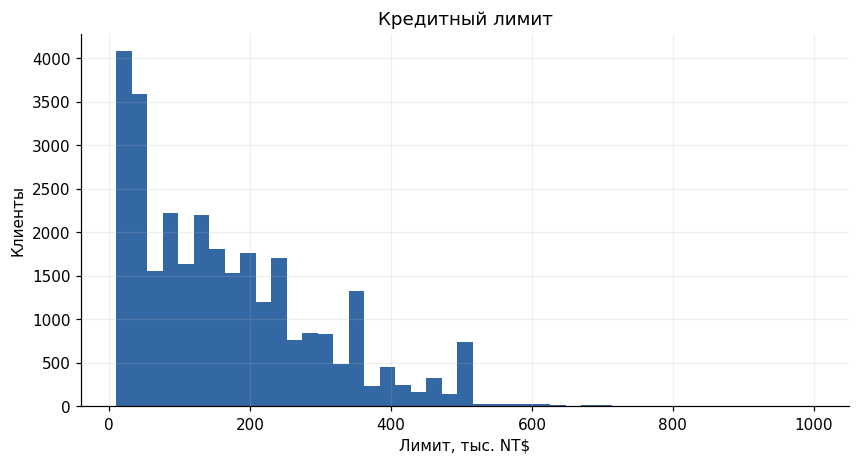

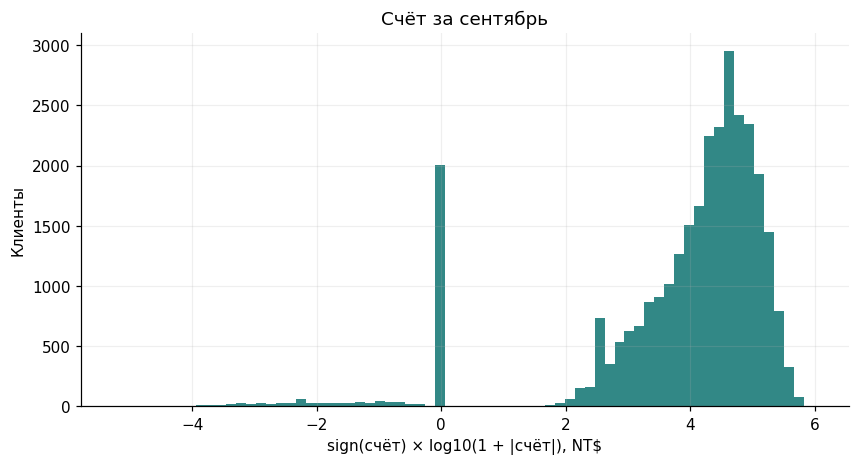

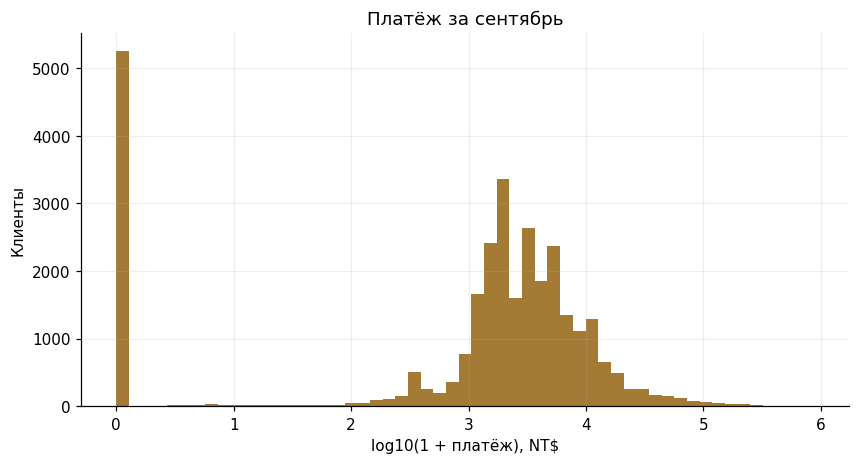

In [5]:
fig, ax = plt.subplots()
ax.hist(df.LIMIT_BAL / 1_000, bins=45, color='#3468a5')
ax.set(title='Кредитный лимит',
       xlabel='Лимит, тыс. NT$', ylabel='Клиенты')
plt.show()

signed_bill = np.sign(df.BILL_AMT1) * np.log10(1 + np.abs(df.BILL_AMT1))
fig, ax = plt.subplots()
ax.hist(signed_bill, bins=70, color='#328886')
ax.set(title='Счёт за сентябрь',
       xlabel='sign(счёт) × log10(1 + |счёт|), NT$', ylabel='Клиенты')
plt.show()

fig, ax = plt.subplots()
ax.hist(np.log10(1 + df.PAY_AMT1), bins=55, color='#a47b35')
ax.set(title='Платёж за сентябрь',
       xlabel='log10(1 + платёж), NT$', ylabel='Клиенты')
plt.show()

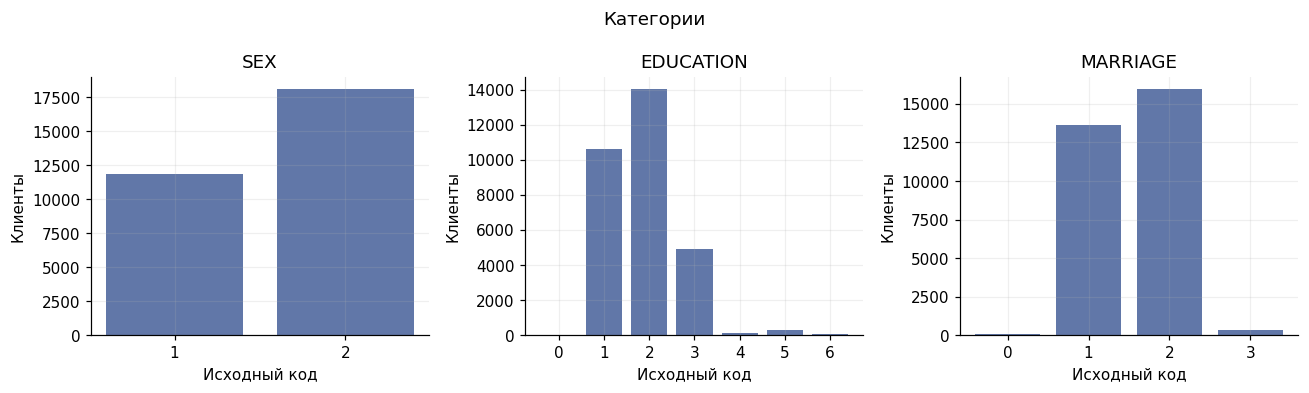

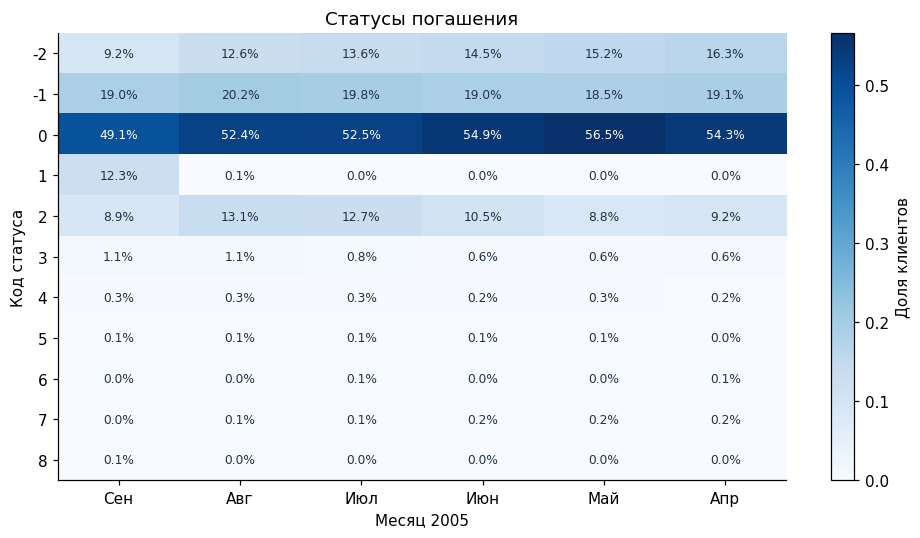

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ['SEX', 'EDUCATION', 'MARRIAGE']):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='#6177a8')
    ax.set(title=col, xlabel='Исходный код', ylabel='Клиенты')
fig.suptitle('Категории')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
status_share = status_counts.div(status_counts.sum(axis=0), axis=1)
im = ax.imshow(status_share, cmap='Blues', aspect='auto')
ax.grid(False)
ax.set(xticks=range(6), xticklabels=['Сен', 'Авг', 'Июл', 'Июн', 'Май', 'Апр'],
       yticks=range(len(status_share)), yticklabels=status_share.index,
       xlabel='Месяц 2005', ylabel='Код статуса', title='Статусы погашения')
for row in range(len(status_share)):
    for col in range(6):
        value = status_share.iloc[row, col]
        ax.text(col, row, f'{value:.1%}', ha='center', va='center',
                color='white' if value > .3 else '#233047', fontsize=8)
fig.colorbar(im, ax=ax, label='Доля клиентов')
fig.tight_layout()
plt.show()

Разбиение 60/20/20 со стратификацией, random_state=42, ID в модель не входит

In [7]:
train_ids, rest_ids = train_test_split(
    df.ID.to_numpy(), test_size=.4, stratify=df.target, random_state=SEED,
)
indexed = df.set_index('ID', drop=False)
val_ids, test_ids = train_test_split(
    rest_ids, test_size=.5, stratify=indexed.loc[rest_ids, 'target'], random_state=SEED,
)
SPLITS = {'train': train_ids, 'validation': val_ids, 'test': test_ids}
assert len(np.unique(np.concatenate(list(SPLITS.values())))) == len(df)
split_manifest = pd.concat([
    pd.DataFrame({'ID': ids, 'split': name}) for name, ids in SPLITS.items()
]).sort_values('ID').reset_index(drop=True)
split_manifest.to_csv(DATA / 'splits.csv', index=False)
split_hash = sha256(split_manifest.to_csv(index=False).encode()).hexdigest()

display(pd.DataFrame([
    {'split': name, 'clients': len(ids),
     'positive_rate': indexed.loc[ids, 'target'].mean() if name != 'test' else np.nan}
    for name, ids in SPLITS.items()
]))

profiles = pd.util.hash_pandas_object(df[RAW_FEATURES], index=False)
profile_by_id = pd.Series(profiles.to_numpy(), index=df.ID)
profile_overlap = {}
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    overlap = set(profile_by_id.loc[SPLITS[left]]) & set(profile_by_id.loc[SPLITS[right]])
    n_right = int(profile_by_id.loc[SPLITS[right]].isin(overlap).sum())
    profile_overlap[f'{left} -> {right}'] = n_right

,split,clients,positive_rate
0,train,18000,0.2212
1,validation,6000,0.2212
2,test,6000,NaN


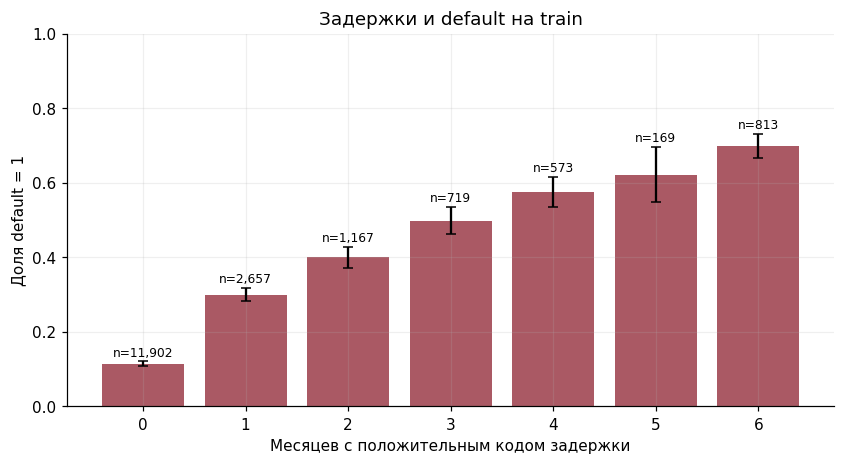

,n,event_rate
delay_months,,
0,11902,0.1144
1,2657,0.2992
2,1167,0.3993
3,719,0.4979
4,573,0.5742
5,169,0.6213
6,813,0.6986


In [8]:
train_raw = indexed.loc[train_ids].copy()
train_raw['delay_months'] = train_raw[STATUS].gt(0).sum(axis=1)
delay_eda = train_raw.groupby('delay_months').target.agg(n='size', event_rate='mean')

delay_eda['se'] = np.sqrt(delay_eda.event_rate * (1 - delay_eda.event_rate) / delay_eda.n)
fig, ax = plt.subplots()
ax.bar(delay_eda.index, delay_eda.event_rate, color='#aa5964',
       yerr=1.96 * delay_eda.se, capsize=3)
for x, row in delay_eda.iterrows():
    ax.text(x, row.event_rate + 1.96 * row.se + .015, f'n={int(row.n):,}', ha='center', fontsize=8)
ax.set(title='Задержки и default на train',
       xlabel='Месяцев с положительным кодом задержки', ylabel='Доля default = 1', ylim=(0, 1))
plt.show()
display(delay_eda[['n', 'event_rate']])

Признаки и SQL

А содержит общие сведения и сентябрь, всего 8 признаков
Б содержит все 6 месяцев и 6 агрегатов, всего 29 признаков
PAY_0 относится к сентябрю, PAY_2 к августу, PAY_6 к апрелю

Агрегаты: число месяцев с задержкой, максимум положительных статусов, средний платёж, счёт сентября минус апреля, счёт сентября / лимит, платёж сентября минус апреля
При нулевом лимите отношение заполняется медианой train
Сравнение А и Б включает историю и агрегаты вместе

In [9]:
month_map = pd.DataFrame([
    ('2005-04-01', 'PAY_6', 'BILL_AMT6', 'PAY_AMT6'),
    ('2005-05-01', 'PAY_5', 'BILL_AMT5', 'PAY_AMT5'),
    ('2005-06-01', 'PAY_4', 'BILL_AMT4', 'PAY_AMT4'),
    ('2005-07-01', 'PAY_3', 'BILL_AMT3', 'PAY_AMT3'),
    ('2005-08-01', 'PAY_2', 'BILL_AMT2', 'PAY_AMT2'),
    ('2005-09-01', 'PAY_0', 'BILL_AMT1', 'PAY_AMT1'),
], columns=['month', 'status_column', 'bill_column', 'payment_column'])
month_map['month'] = pd.to_datetime(month_map.month)
display(month_map)
monthly = pd.concat([
    pd.DataFrame({
        'client_id': df.ID, 'month': row.month,
        'payment_status': df[row.status_column],
        'bill_amount': df[row.bill_column],
        'payment_amount': df[row.payment_column],
    }) for row in month_map.itertuples(index=False)
], ignore_index=True).sort_values(['client_id', 'month']).reset_index(drop=True)
limits = df[['ID', 'LIMIT_BAL']].rename(columns={'ID': 'client_id'})
con = duckdb.connect(':memory:')
con.register('monthly', monthly)
con.register('limits', limits)

,month,status_column,bill_column,payment_column
0,2005-04-01,PAY_6,BILL_AMT6,PAY_AMT6
1,2005-05-01,PAY_5,BILL_AMT5,PAY_AMT5
2,2005-06-01,PAY_4,BILL_AMT4,PAY_AMT4
3,2005-07-01,PAY_3,BILL_AMT3,PAY_AMT3
4,2005-08-01,PAY_2,BILL_AMT2,PAY_AMT2
5,2005-09-01,PAY_0,BILL_AMT1,PAY_AMT1


In [10]:
aggregate_sql = """
WITH chronological AS (
    SELECT *, bill_amount - LAG(bill_amount) OVER (
        PARTITION BY client_id ORDER BY month
    ) AS bill_delta
    FROM monthly
), history AS (
    SELECT client_id,
           COUNT(*) AS month_count,
           SUM(CASE WHEN payment_status > 0 THEN 1 ELSE 0 END) AS delay_months,
           MAX(GREATEST(payment_status, 0)) AS max_delay,
           AVG(payment_amount) AS mean_payment,
           SUM(bill_delta) AS bill_change,
           MAX(CASE WHEN month = DATE '2005-09-01' THEN bill_amount END) AS last_bill,
           MAX(CASE WHEN month = DATE '2005-09-01' THEN payment_amount END)
             - MAX(CASE WHEN month = DATE '2005-04-01' THEN payment_amount END)
             AS payment_change
    FROM chronological
    GROUP BY client_id
)
SELECT h.client_id, h.delay_months, h.max_delay, h.mean_payment, h.bill_change,
       h.last_bill / NULLIF(l.LIMIT_BAL, 0) AS last_utilization,
       h.payment_change, h.month_count
FROM history h
JOIN limits l USING (client_id)
ORDER BY h.client_id
"""
aggregates = con.execute(aggregate_sql).df().rename(columns={'client_id': 'ID'})
AGGREGATES = ['delay_months', 'max_delay', 'mean_payment', 'bill_change',
              'last_utilization', 'payment_change']
features = df[['ID', *RAW_FEATURES]].merge(
    aggregates[['ID', *AGGREGATES]], on='ID', how='left', validate='one_to_one',
).set_index('ID')
assert len(features) == len(df) and features.index.is_unique
con.close()

In [11]:
reference = pd.DataFrame({
    'ID': df.ID,
    'delay_months': df[STATUS].gt(0).sum(axis=1),
    'max_delay': df[STATUS].clip(lower=0).max(axis=1),
    'mean_payment': df[PAYMENTS].mean(axis=1),
    'bill_change': df.BILL_AMT1 - df.BILL_AMT6,
    'last_utilization': df.BILL_AMT1 / df.LIMIT_BAL.replace(0, np.nan),
    'payment_change': df.PAY_AMT1 - df.PAY_AMT6,
}).set_index('ID')
np.testing.assert_allclose(
    features.loc[reference.index, AGGREGATES], reference[AGGREGATES], equal_nan=True,
)

sample = monthly.loc[monthly.client_id.isin([1, 2, 100])].copy()
sample['bill_delta'] = sample.groupby('client_id').bill_amount.diff()
display(sample)
display(features.loc[[1, 2, 100], AGGREGATES])

FEATURE_SETS = {
    'A': GENERAL + ['PAY_0', 'BILL_AMT1', 'PAY_AMT1'],
    'B': RAW_FEATURES + AGGREGATES,
}
CATEGORICAL = ['SEX', 'EDUCATION', 'MARRIAGE', *STATUS]
assert all({'ID', 'target'}.isdisjoint(cols) for cols in FEATURE_SETS.values())

model_data = features.copy()
for col in CATEGORICAL:
    model_data[col] = model_data[col].map(lambda v: '__MISSING__' if pd.isna(v) else str(int(v)))
y_train = indexed.loc[train_ids, 'target'].to_numpy()
y_val = indexed.loc[val_ids, 'target'].to_numpy()
X_train = model_data.loc[train_ids]
X_val = model_data.loc[val_ids]

,client_id,month,payment_status,bill_amount,payment_amount,bill_delta
0,1,2005-04-01,-2,0,0,NaN
1,1,2005-05-01,-2,0,0,0.0000
2,1,2005-06-01,-1,0,0,0.0000
3,1,2005-07-01,-1,689,0,689.0000
4,1,2005-08-01,2,3102,689,"2,413.0000"
5,1,2005-09-01,2,3913,0,811.0000
6,2,2005-04-01,2,3261,2000,NaN
7,2,2005-05-01,0,3455,0,194.0000
8,2,2005-06-01,0,3272,1000,-183.0000
9,2,2005-07-01,0,2682,1000,-590.0000


,delay_months,max_delay,mean_payment,bill_change,last_utilization,payment_change
ID,,,,,,
1,2.0000,2,114.8333,"3,913.0000",0.1956,0
2,2.0000,2,833.3333,-579.0000,0.0223,-2000
100,0.0000,0,947.5000,"17,823.0000",0.8986,1699


Проверка ID 1: два месяца задержки, максимум 2, изменение счёта 3913, средний платёж 689 / 6, счёт / лимит 3913 / 20000

Модели

Константа равна доле единиц train
LR использует One-Hot для категорий и StandardScaler для чисел
SEX, EDUCATION, MARRIAGE и PAY считаю категориями, остальные признаки числовые
Преобразования и модели обучаются на train, базовые настройки А и Б одинаковы

In [12]:
def make_logit(cols, C=1.0):
    cats = [c for c in cols if c in CATEGORICAL]
    nums = [c for c in cols if c not in CATEGORICAL]
    preprocessing = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), nums),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), cats),
    ])
    return Pipeline([
        ('preprocess', preprocessing),
        ('model', LogisticRegression(C=C, max_iter=2000, solver='lbfgs', random_state=SEED)),
    ])

def make_catboost(cols, depth=6, l2_leaf_reg=3):
    return CatBoostClassifier(
        iterations=500, depth=depth, learning_rate=.05, l2_leaf_reg=l2_leaf_reg,
        loss_function='Logloss', eval_metric='AUC', random_seed=SEED,
        cat_features=[c for c in cols if c in CATEGORICAL],
        task_type='CPU', thread_count=4, verbose=False, allow_writing_files=False,
    )

def probability_metrics(y, p):
    p = np.asarray(p, dtype=float)
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return {'roc_auc': roc_auc_score(y, p),
            'average_precision': average_precision_score(y, p),
            'brier': brier_score_loss(y, p)}

fitted = {}
val_predictions = {}
experiment_rows = []
train_prevalence = float(y_train.mean())
val_predictions['constant'] = np.full(len(y_val), train_prevalence)
experiment_rows.append({
    'key': 'constant', 'model': 'Константа', 'features': '-', 'parameters': 'train prevalence',
    'kind': 'base', 'hypothesis': 'Ориентир без признаков', 'fit_seconds': 0.,
    **probability_metrics(y_val, val_predictions['constant']),
})

def fit_experiment(key, family, feature_set, parameters, hypothesis, kind='base'):
    cols = FEATURE_SETS[feature_set]
    model = make_logit(cols, **parameters) if family == 'LR' else make_catboost(cols, **parameters)
    started = time.perf_counter()
    model.fit(X_train[cols], y_train)
    seconds = time.perf_counter() - started
    p = model.predict_proba(X_val[cols])[:, 1]
    fitted[key] = {'estimator': model, 'family': family, 'features': feature_set,
                   'columns': cols.copy(), 'parameters': parameters.copy()}
    val_predictions[key] = p
    experiment_rows.append({
        'key': key, 'model': 'Логистическая регрессия' if family == 'LR' else 'CatBoost',
        'features': feature_set, 'parameters': json.dumps(parameters),
        'kind': kind, 'hypothesis': hypothesis, 'fit_seconds': seconds,
        **probability_metrics(y_val, p),
    })

BASE_KEYS = ['constant', 'lr_A', 'lr_B', 'cb_A', 'cb_B']
fit_experiment('lr_A', 'LR', 'A', {'C': 1.0}, 'Последний месяц: линейный ориентир')
fit_experiment('lr_B', 'LR', 'B', {'C': 1.0}, 'История и агрегаты добавят полезную информацию')
fit_experiment('cb_A', 'CB', 'A', {}, 'Нелинейности и взаимодействия последнего месяца')
fit_experiment('cb_B', 'CB', 'B', {}, 'Нелинейности в полной истории')
base_validation = pd.DataFrame(experiment_rows).set_index('key')
display(base_validation[['model', 'features', 'roc_auc', 'average_precision', 'brier', 'fit_seconds']])

,model,features,roc_auc,average_precision,brier,fit_seconds
key,,,,,,
constant,Константа,-,0.5000,0.2212,0.1723,0.0000
lr_A,Логистическая регрессия,A,0.7346,0.4901,0.1433,0.0523
lr_B,Логистическая регрессия,B,0.7577,0.5141,0.1404,0.1227
cb_A,CatBoost,A,0.7544,0.5101,0.1417,3.3117
cb_B,CatBoost,B,0.7783,0.5367,0.1371,5.3442


Проверяю на Б три изменения

C=0.1 для LR, сильнее регуляризация коррелированных признаков
Depth=4 для CatBoost, меньше сложность деревьев
L2=10 для CatBoost, сильнее сглаживание листьев

In [13]:
fit_experiment('lr_B_C01', 'LR', 'B', {'C': .1},
               'Более сильная регуляризация при коррелированной истории', kind='check')
fit_experiment('cb_B_depth4', 'CB', 'B', {'depth': 4},
               'Меньшая глубина уменьшит переобучение и сложность', kind='check')
fit_experiment('cb_B_l2_10', 'CB', 'B', {'l2_leaf_reg': 10},
               'Сглаживание листьев улучшит обобщение вероятностей', kind='check')
validation = pd.DataFrame(experiment_rows).set_index('key')
checks = validation.loc[validation.kind.eq('check')].copy()
checks['reference'] = ['lr_B', 'cb_B', 'cb_B']
checks['delta_auc'] = [row.roc_auc - validation.loc[row.reference, 'roc_auc']
                       for row in checks.itertuples()]
checks['delta_brier'] = [row.brier - validation.loc[row.reference, 'brier']
                         for row in checks.itertuples()]
display(checks[['hypothesis', 'parameters', 'roc_auc', 'delta_auc', 'brier', 'delta_brier', 'fit_seconds']])

,hypothesis,parameters,roc_auc,delta_auc,brier,delta_brier,fit_seconds
key,,,,,,,
lr_B_C01,Более сильная регуляризация при коррелированно...,"{""C"": 0.1}",0.7583,0.0006,0.1402,-0.0003,0.1035
cb_B_depth4,Меньшая глубина уменьшит переобучение и сложность,"{""depth"": 4}",0.7791,0.0007,0.1368,-0.0003,3.9042
cb_B_l2_10,Сглаживание листьев улучшит обобщение вероятно...,"{""l2_leaf_reg"": 10}",0.7790,0.0007,0.1368,-0.0003,4.3624


Выбираю по validation ROC-AUC, при равенстве по Brier и сложности

,model,features,parameters,roc_auc,brier
key,,,,,
cb_B_depth4,CatBoost,B,"{""depth"": 4}",0.7791,0.1368


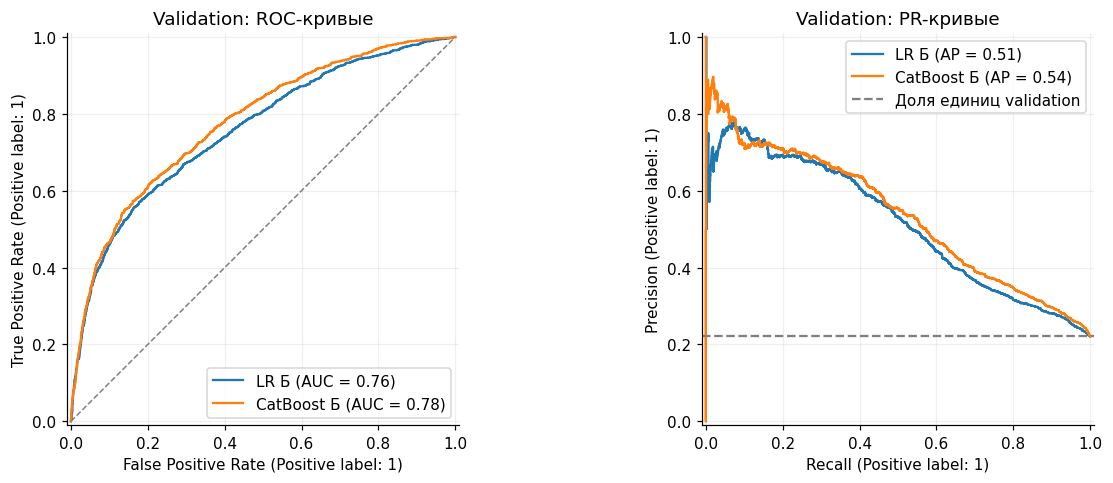

In [14]:
selection = validation.drop(index='constant').copy()
selection['n_features'] = selection.features.map(lambda s: len(FEATURE_SETS[s]))
selection['family_priority'] = [0 if fitted[key]['family'] == 'LR' else 1 for key in selection.index]
selection = selection.sort_values(
    ['roc_auc', 'brier', 'n_features', 'family_priority'], ascending=[False, True, True, True],
)
selected_key = selection.index[0]
selected = fitted[selected_key]
selected_model = selected['estimator']
selected_columns = selected['columns']
selected_val_p = val_predictions[selected_key]
display(selection.head(1)[['model', 'features', 'parameters', 'roc_auc', 'brier']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for key, label in [('lr_B', 'LR Б'), ('cb_B', 'CatBoost Б')]:
    RocCurveDisplay.from_predictions(y_val, val_predictions[key], name=label, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, val_predictions[key], name=label, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[1].axhline(y_val.mean(), linestyle='--', color='gray', label='Доля единиц validation')
axes[0].set_title('Validation: ROC-кривые')
axes[1].set_title('Validation: PR-кривые')
axes[1].legend()
fig.tight_layout()
plt.show()

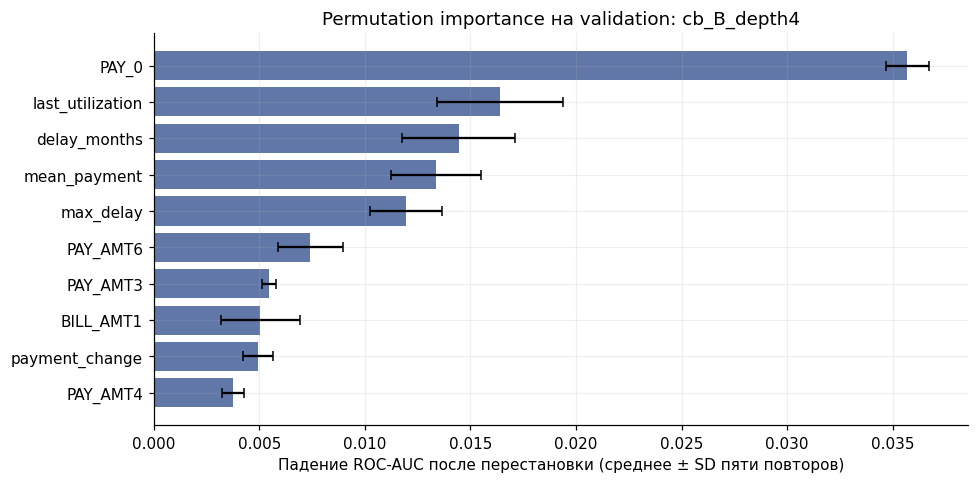

In [15]:
importance = permutation_importance(
    selected_model, X_val[selected_columns], y_val,
    scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1,
)
importance_table = pd.DataFrame({
    'feature': selected_columns, 'mean_auc_drop': importance.importances_mean,
    'std_auc_drop': importance.importances_std,
}).sort_values('mean_auc_drop', ascending=False).reset_index(drop=True)
top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.feature, top.mean_auc_drop, xerr=top.std_auc_drop, color='#6177a8', capsize=3)
ax.axvline(0, color='gray', linewidth=1)
ax.set(title=f'Permutation importance на validation: {selected_key}',
       xlabel='Падение ROC-AUC после перестановки (среднее ± SD пяти повторов)')
fig.tight_layout()
plt.show()

PAY_0 описывает последнее погашение, last_utilization загрузку лимита, delay_months повторение задержек, mean_payment средний платёж, важность не означает причинное влияние

Пороги выбираю на validation по минимуму FP + цена_FN * FN
Цена FP равна 1, цена FN равна 5 или 10, высокий риск при p >= порога

In [16]:
def choose_cost_threshold(y, p, cost_fp=1, cost_fn=5):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    order = np.argsort(-p, kind='stable')
    scores, labels = p[order], y[order]
    
    ends = np.r_[np.flatnonzero(scores[:-1] != scores[1:]), len(p) - 1]
    predicted_positive = np.r_[0, ends + 1, len(p)]
    tp = np.r_[0, np.cumsum(labels)[ends], labels.sum()]
    thresholds = np.r_[np.nextafter(1., 2.), scores[ends], 0.]
    fp = predicted_positive - tp
    fn = labels.sum() - tp
    costs = cost_fp * fp + cost_fn * fn
    best = int(np.flatnonzero(costs == costs.min())[0])
    return {'threshold': float(thresholds[best]), 'validation_cost': int(costs[best]),
            'validation_cost_per_client': float(costs[best] / len(y)),
            'validation_fp': int(fp[best]), 'validation_fn': int(fn[best])}

SCENARIOS = {'FP1_FN5': {'fp': 1, 'fn': 5}, 'FP1_FN10': {'fp': 1, 'fn': 10}}
thresholds = {
    name: choose_cost_threshold(y_val, selected_val_p, costs['fp'], costs['fn'])
    for name, costs in SCENARIOS.items()
}
display(pd.DataFrame(thresholds).T)

REPORT_KEYS = BASE_KEYS + ([] if selected_key in BASE_KEYS else [selected_key])
decisions = {
    'seed': SEED, 'data_sha256': EXPECTED_SHA256, 'split_sha256': split_hash,
    'split_sizes': {k: len(v) for k, v in SPLITS.items()},
    'feature_sets': FEATURE_SETS, 'categorical_columns': CATEGORICAL,
    'selected_key': selected_key, 'selected_family': selected['family'],
    'selected_feature_set': selected['features'], 'selected_parameters': selected['parameters'],
    'selected_effective_parameters': selected_model.get_params(),
    'selected_columns': selected_columns,
    'report_keys': REPORT_KEYS, 'thresholds': thresholds, 'scenarios': SCENARIOS,
    'selection_rule': 'max validation ROC-AUC, then min Brier, feature count, LR priority',
    'validation_results': validation.reset_index().to_dict(orient='records'),
    'versions': VERSIONS,
}

if selected['family'] == 'LR':
    decisions['selected_effective_parameters'] = selected_model.named_steps['model'].get_params()
decision_file = ARTIFACTS / 'validation_decisions.json'
decision_payload = json.dumps(decisions, ensure_ascii=False, indent=2, allow_nan=False)
decision_file.write_text(decision_payload, encoding='utf-8')
frozen_decision_hash = sha256(decision_payload.encode()).hexdigest()

,threshold,validation_cost,validation_cost_per_client,validation_fp,validation_fn
FP1_FN5,0.1455,"3,306.0000",0.5510,"1,931.0000",275.0000
FP1_FN10,0.0785,"4,024.0000",0.6707,"3,504.0000",52.0000


Оценка на test после фиксации модели и порогов

In [17]:
assert sha256(decision_file.read_bytes()).hexdigest() == frozen_decision_hash
y_test = indexed.loc[test_ids, 'target'].to_numpy()
X_test = model_data.loc[test_ids]
test_predictions = {}
test_rows = []
for key in REPORT_KEYS:
    if key == 'constant':
        p = np.full(len(y_test), train_prevalence)
    else:
        item = fitted[key]
        p = item['estimator'].predict_proba(X_test[item['columns']])[:, 1]
    test_predictions[key] = p
    row = validation.loc[key]
    test_rows.append({
        'key': key, 'model': row.model, 'features': row.features,
        'validation_roc_auc': row.roc_auc,
        **{f'test_{metric}': value for metric, value in probability_metrics(y_test, p).items()},
    })
final_table = pd.DataFrame(test_rows).set_index('key')
selected_test_p = test_predictions[selected_key]
display(final_table)

,model,features,validation_roc_auc,test_roc_auc,test_average_precision,test_brier
key,,,,,,
constant,Константа,-,0.5000,0.5000,0.2212,0.1723
lr_A,Логистическая регрессия,A,0.7346,0.7597,0.5225,0.1374
lr_B,Логистическая регрессия,B,0.7577,0.7782,0.5549,0.1342
cb_A,CatBoost,A,0.7544,0.7794,0.5601,0.1342
cb_B,CatBoost,B,0.7783,0.7934,0.5734,0.1316
cb_B_depth4,CatBoost,B,0.7791,0.7913,0.5727,0.1318


Калибровка по 10 квантильным группам, без дополнительной настройки вероятностей

,n,mean_probability,event_rate,gap
bin,,,,
"(0.02, 0.0589]",600,0.0466,0.0433,0.0033
"(0.0589, 0.0757]",600,0.0673,0.0717,-0.0044
"(0.0757, 0.0948]",600,0.0852,0.0683,0.0168
"(0.0948, 0.118]",600,0.1063,0.1000,0.0063
"(0.118, 0.143]",600,0.1305,0.1483,-0.0178
"(0.143, 0.172]",600,0.1569,0.1700,-0.0131
"(0.172, 0.223]",600,0.1945,0.1883,0.0061
"(0.223, 0.323]",600,0.2683,0.2750,-0.0067
"(0.323, 0.571]",600,0.4163,0.4417,-0.0254


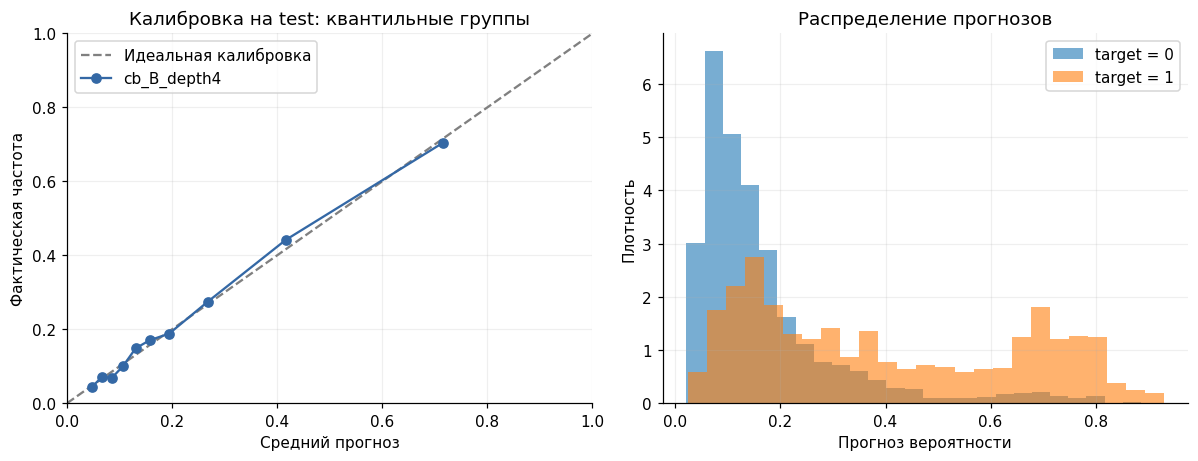

In [18]:
calibration = pd.DataFrame({'target': y_test, 'probability': selected_test_p})
calibration['bin'] = pd.qcut(calibration.probability, q=10, duplicates='drop')
calibration_table = calibration.groupby('bin', observed=True).agg(
    n=('target', 'size'), mean_probability=('probability', 'mean'),
    event_rate=('target', 'mean'),
)
calibration_table['gap'] = calibration_table.mean_probability - calibration_table.event_rate
calibration_ece = float(np.average(abs(calibration_table.gap), weights=calibration_table.n))
observed, predicted = calibration_curve(y_test, selected_test_p, n_bins=10, strategy='quantile')
display(calibration_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Идеальная калибровка')
axes[0].plot(predicted, observed, 'o-', color='#3468a5', label=selected_key)
axes[0].set(xlabel='Средний прогноз', ylabel='Фактическая частота',
            title='Калибровка на test: квантильные группы', xlim=(0, 1), ylim=(0, 1))
axes[0].legend()
axes[1].hist(selected_test_p[y_test == 0], bins=25, alpha=.6, density=True, label='target = 0')
axes[1].hist(selected_test_p[y_test == 1], bins=25, alpha=.6, density=True, label='target = 1')
axes[1].set(xlabel='Прогноз вероятности', ylabel='Плотность', title='Распределение прогнозов')
axes[1].legend()
fig.tight_layout()
plt.show()

In [19]:
def bootstrap_auc(y, p, n_resamples=1000, seed=SEED):
    
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    scores = []
    skipped = 0
    for _ in range(n_resamples):
        idx = rng.integers(0, len(y), size=len(y))
        if np.unique(y[idx]).size < 2:
            skipped += 1
            continue
        scores.append(roc_auc_score(y[idx], p[idx]))
    return np.quantile(scores, [.025, .975]), skipped

auc_interval, skipped_bootstraps = bootstrap_auc(y_test, selected_test_p)

Bootstrap по клиентам, 1000 выборок, модель фиксирована, интервал не оценивает качество в будущие месяцы

In [20]:
def threshold_metrics(y, pred, cost_fp=1, cost_fn=5):
    pred = np.asarray(pred, dtype=bool)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'n': len(y), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp), 'tn': int(tn),
        'cost_per_client': float((cost_fp * fp + cost_fn * fn) / len(y)),
        'precision': float(tp / (tp + fp)) if tp + fp else np.nan,
        'recall': float(tp / (tp + fn)) if tp + fn else np.nan,
        'high_risk_share': float(pred.mean()),
    }

cost_rows = []
for scenario, prices in SCENARIOS.items():
    chosen = thresholds[scenario]['threshold']
    strategies = [
        ('Порог с validation', chosen, selected_test_p >= chosen),
        ('Порог 0.5', .5, selected_test_p >= .5),
        ('Все высокого риска', np.nan, np.ones(len(y_test), dtype=bool)),
        ('Все низкого риска', np.nan, np.zeros(len(y_test), dtype=bool)),
    ]
    for strategy, threshold, prediction in strategies:
        cost_rows.append({
            'scenario': scenario, 'strategy': strategy, 'threshold': threshold,
            **threshold_metrics(y_test, prediction, prices['fp'], prices['fn']),
        })
cost_table = pd.DataFrame(cost_rows)
display(cost_table[['scenario', 'strategy', 'threshold', 'cost_per_client',
                    'precision', 'recall', 'high_risk_share', 'fp', 'fn']])

,scenario,strategy,threshold,cost_per_client,precision,recall,high_risk_share,fp,fn
0,FP1_FN5,Порог с validation,0.1455,0.5360,0.3604,0.7988,0.4902,1881,267
1,FP1_FN5,Порог 0.5,0.5000,0.7378,0.6954,0.3647,0.1160,212,843
2,FP1_FN5,Все высокого риска,NaN,0.7788,0.2212,1.0000,1.0000,4673,0
3,FP1_FN5,Все низкого риска,NaN,1.1058,NaN,0.0000,0.0000,0,1327
4,FP1_FN10,Порог с validation,0.0785,0.7045,0.2656,0.9420,0.7845,3457,77
5,FP1_FN10,Порог 0.5,0.5000,1.4403,0.6954,0.3647,0.1160,212,843
6,FP1_FN10,Все высокого риска,NaN,0.7788,0.2212,1.0000,1.0000,4673,0
7,FP1_FN10,Все низкого риска,NaN,2.2117,NaN,0.0000,0.0000,0,1327


Ошибки на test при пороге сценария FN=5, срезы по лимиту, наличию задержек и возрасту

In [21]:
slice_frame = features.loc[test_ids].copy()
slice_frame['target'] = y_test
slice_frame['probability'] = selected_test_p
slice_frame['high_risk'] = selected_test_p >= thresholds['FP1_FN5']['threshold']
slice_frame['limit_group'] = pd.cut(
    slice_frame.LIMIT_BAL, [-np.inf, 50_000, 200_000, np.inf],
    labels=['≤50k NT$', '50k–200k NT$', '>200k NT$'],
)
slice_frame['prior_delay'] = np.where(slice_frame.delay_months.gt(0), 'Есть задержки', 'Нет задержек')
slice_frame['age_group'] = pd.cut(
    slice_frame.AGE, [-np.inf, 29, 49, np.inf], labels=['<30', '30–49', '≥50'],
)
slice_rows = []
for dimension in ['limit_group', 'prior_delay', 'age_group']:
    for group_name, group in slice_frame.groupby(dimension, observed=True, sort=True):
        errors = threshold_metrics(group.target, group.high_risk)
        slice_rows.append({
            'dimension': dimension, 'group': str(group_name), 'n': len(group),
            'events': int(group.target.sum()), 'event_rate': group.target.mean(),
            'mean_probability': group.probability.mean(),
            'roc_auc': roc_auc_score(group.target, group.probability) if group.target.nunique() == 2 else np.nan,
            'brier': brier_score_loss(group.target, group.probability),
            'fp': errors['fp'], 'fn': errors['fn'],
            'fpr': errors['fp'] / (errors['fp'] + errors['tn']) if errors['fp'] + errors['tn'] else np.nan,
            'fnr': errors['fn'] / (errors['fn'] + errors['tp']) if errors['fn'] + errors['tp'] else np.nan,
            'precision': errors['precision'], 'recall': errors['recall'],
            'high_risk_share': errors['high_risk_share'],
            'cost_per_client': errors['cost_per_client'],
        })
slice_table = pd.DataFrame(slice_rows)
display(slice_table)

,dimension,group,n,events,event_rate,mean_probability,roc_auc,brier,fp,fn,fpr,fnr,precision,recall,high_risk_share,cost_per_client
0,limit_group,≤50k NT$,1523,470,0.3086,0.3176,0.7591,0.1723,788,33,0.7483,0.0702,0.3567,0.9298,0.8043,0.6257
1,limit_group,50k–200k NT$,2527,562,0.2224,0.2156,0.7799,0.1335,711,137,0.3618,0.2438,0.3741,0.7562,0.4495,0.5524
2,limit_group,>200k NT$,1950,295,0.1513,0.1457,0.7886,0.0979,382,97,0.2308,0.3288,0.3414,0.6712,0.2974,0.4446
3,prior_delay,Есть задержки,2035,862,0.4236,0.4251,0.7631,0.1945,1069,16,0.9113,0.0186,0.4418,0.9814,0.9410,0.5646
4,prior_delay,Нет задержек,3965,465,0.1173,0.1129,0.6709,0.0996,812,251,0.2320,0.5398,0.2086,0.4602,0.2588,0.5213
5,age_group,<30,1926,421,0.2186,0.2294,0.7901,0.1317,644,81,0.4279,0.1924,0.3455,0.8076,0.5109,0.5447
6,age_group,30–49,3502,757,0.2162,0.2082,0.7960,0.1284,1050,156,0.3825,0.2061,0.3640,0.7939,0.4714,0.5226
7,age_group,≥50,572,149,0.2605,0.2482,0.7678,0.1530,187,30,0.4421,0.2013,0.3889,0.7987,0.5350,0.5892


In [22]:
val_delta_lr = validation.loc['lr_B', 'roc_auc'] - validation.loc['lr_A', 'roc_auc']
val_delta_cb = validation.loc['cb_B', 'roc_auc'] - validation.loc['cb_A', 'roc_auc']
test_delta_lr = final_table.loc['lr_B', 'test_roc_auc'] - final_table.loc['lr_A', 'test_roc_auc']
test_delta_cb = final_table.loc['cb_B', 'test_roc_auc'] - final_table.loc['cb_A', 'test_roc_auc']
cb_over_lr = final_table.loc['cb_B', 'test_roc_auc'] - final_table.loc['lr_B', 'test_roc_auc']
score = final_table.loc[selected_key]
no_delays = slice_table.loc[slice_table['group'].eq('Нет задержек')].iloc[0]
conclusions = f"""История и агрегаты добавили {test_delta_lr:.4f} test ROC-AUC у LR и {test_delta_cb:.4f} у CatBoost
CatBoost Б лучше LR Б на {cb_over_lr:.4f}

Выбран {selected_key}, test ROC-AUC {score.test_roc_auc:.4f}, AP {score.test_average_precision:.4f}, Brier {score.test_brier:.4f}
95% bootstrap-интервал ROC-AUC от {auc_interval[0]:.4f} до {auc_interval[1]:.4f}

Средний прогноз {selected_test_p.mean():.2%}, частота события {y_test.mean():.2%}, ECE {calibration_ece:.4f}
Порог при FN=5 равен {thresholds['FP1_FN5']['threshold']:.4f}, при FN=10 равен {thresholds['FP1_FN10']['threshold']:.4f}

Без прошлых задержек FNR {no_delays.fnr:.1%}, ROC-AUC {no_delays.roc_auc:.4f}
Причины различий групп не проверялись

Один рынок и целевой период 2005 года, переноса на будущие месяцы не проверял
Совпадающие профили при разных ID сохранены, значимость различий моделей не оценивалась"""
display(Markdown(conclusions))

История и агрегаты добавили 0.0185 test ROC-AUC у LR и 0.0139 у CatBoost
CatBoost Б лучше LR Б на 0.0152

Выбран cb_B_depth4, test ROC-AUC 0.7913, AP 0.5727, Brier 0.1318
95% bootstrap-интервал ROC-AUC от 0.7755 до 0.8050

Средний прогноз 21.88%, частота события 22.12%, ECE 0.0111
Порог при FN=5 равен 0.1455, при FN=10 равен 0.0785

Без прошлых задержек FNR 54.0%, ROC-AUC 0.6709
Причины различий групп не проверялись

Один рынок и целевой период 2005 года, переноса на будущие месяцы не проверял
Совпадающие профили при разных ID сохранены, значимость различий моделей не оценивалась

In [23]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient='records', force_ascii=False, double_precision=12))

results = {
    'data_sha256': EXPECTED_SHA256, 'split_sha256': split_hash,
    'decision_sha256': frozen_decision_hash, 'audit': audit, 'profile_overlap': profile_overlap,
    'selected_key': selected_key, 'test_positive_rate': float(y_test.mean()),
    'final_metrics': records(final_table),
    'parameter_checks': records(checks), 'threshold_results': records(cost_table),
    'calibration': records(calibration_table.astype({'n': int}).reset_index(drop=True)),
    'calibration_ece': calibration_ece,
    'mean_test_probability': float(selected_test_p.mean()),
    'roc_auc_bootstrap_95': auc_interval.tolist(),
    'bootstrap_resamples': 1000, 'bootstrap_skipped': skipped_bootstraps,
    'permutation_importance': records(importance_table), 'slices': records(slice_table),
    'history_delta': {'LR_validation': val_delta_lr, 'LR_test': test_delta_lr,
                      'CB_validation': val_delta_cb, 'CB_test': test_delta_cb},
    'conclusions': conclusions,
}
(ARTIFACTS / 'results.json').write_text(
    json.dumps(results, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
)

17245